# MailGuard: finding phishing mails with plain Python

This notebook is part of **PyBench**, my project for **INT108 Python Programming** (LPU). MailGuard reads e-mails from text files, runs six rule classes over them and gives each mail a phishing score from 0 to 100 with the reasons.

It started from practical 14 of the course (*take a sample of ten phishing e-mails and find the most common words*) and uses something from every unit: strings, lists, tuples and dictionaries, functions, classes with inheritance and overriding, files, pickle, exceptions and regular expressions.

- Live site (every topic runs in the browser): https://lushadowx.github.io/PyBench/
- Code: https://github.com/LuShadowX/PyBench

The analysis itself is plain Python. pandas and matplotlib are only used here to show the results as tables and charts.

In [1]:
import os, sys, subprocess

# get the project (Kaggle: turn Internet on in the notebook settings)
if not os.path.isdir("PyBench"):
    subprocess.run(["git", "clone", "-q", "https://github.com/LuShadowX/PyBench"], check=False)

sys.path.insert(0, os.path.abspath("PyBench/python"))
from pybench.mailguard import MailGuard, Mail, Rule, load_mails

DATA = "PyBench/python/data"
print("phishing mails:", len(os.listdir(f"{DATA}/phishing")))
print("normal mails:  ", len(os.listdir(f"{DATA}/safe")))

phishing mails: 10
normal mails:   4


## 1. One mail, step by step

`Mail` splits the headers from the body with a regular expression and exposes the sender's domain and every URL as properties.

In [2]:
mail = Mail.from_file(f"{DATA}/phishing/07_microsoft_password.txt")
print("From:   ", mail.sender)
print("Domain: ", mail.sender_domain)
print("Subject:", mail.subject)
print("URLs:   ", mail.urls)
print()
report = MailGuard().analyse(mail)
print(report)
for finding in report.findings:
    print(" ", finding)

From:    Microsoft 365 <security@micros0ft-account.com>
Domain:  micros0ft-account.com
Subject: Your password expires today
URLs:    ['https://login-microsoftonline.account-verify.com@45.77.12.9/keep']

07_microsoft_password.txt: 90 (phishing)
  +8 urgent / threatening language: 'expires'
  +8 urgent / threatening language: 'suspended'
  +20 asks for private details: mentions credentials, password
  +18 suspicious link: '@' inside a URL, the part before it is ignored by the browser
  +10 suspicious link: domain made to look official (login-microsoftonline.account-verify.com@45.77.12.9)
  +14 sender does not match: claims to be MICROSOFT but sent from micros0ft-account.com
  +12 sender does not match: look-alike characters in micros0ft-account.com (0 for o, 1 for l)


## 2. Every mail in both folders

In [3]:
import pandas as pd

guard = MailGuard()
rows = []
for label, folder in [("phishing", f"{DATA}/phishing"), ("normal", f"{DATA}/safe")]:
    reports, errors = guard.analyse_folder(folder)
    for r in reports:
        rows.append({"set": label, "mail": r.mail, "subject": r.subject[:45], "score": r.score,
                     "verdict": r.verdict, "reasons": len(r.findings)})

df = pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)
df

,set,mail,subject,score,verdict,reasons
0,phishing,07_microsoft_password.txt,Your password expires today,90,phishing,7
1,phishing,01_sbi_kyc.txt,URGENT: Your SBI account will be blocked toda,89,phishing,7
2,phishing,04_lpu_fee.txt,Final notice: pending semester fee,81,phishing,7
3,phishing,03_netflix.txt,Your membership has been suspended,74,phishing,6
4,phishing,02_lottery.txt,"Congratulations!! You WON Rs 25,00,000 in the",71,phishing,7
5,phishing,08_income_tax.txt,You are eligible for an income tax refund of,71,phishing,6
6,phishing,09_job_offer.txt,You are selected for a work from home job - R,68,phishing,6
7,phishing,05_amazon_refund.txt,"Refund of Rs 2,349 is waiting for you",60,phishing,5
8,phishing,06_dhl_parcel.txt,Your parcel is on hold - action required,54,phishing,5
9,phishing,10_crypto.txt,Double your Bitcoin in 24 hours,50,phishing,5


In [4]:
summary = pd.crosstab(df["set"], df["verdict"])
print(summary, "\n")

phish = df[df.set == "phishing"]
normal = df[df.set == "normal"]
caught = (phish.verdict == "phishing").sum()
false_alarms = (normal.verdict != "looks safe").sum()
print(f"caught {caught} of {len(phish)} phishing mails")
print(f"false alarms: {false_alarms} of {len(normal)} normal mails")
print(f"lowest phishing score {phish.score.min()}, highest normal score {normal.score.max()}")

verdict   looks safe  phishing
set                           
normal             4         0
phishing           0        10 

caught 10 of 10 phishing mails
false alarms: 0 of 4 normal mails
lowest phishing score 50, highest normal score 0


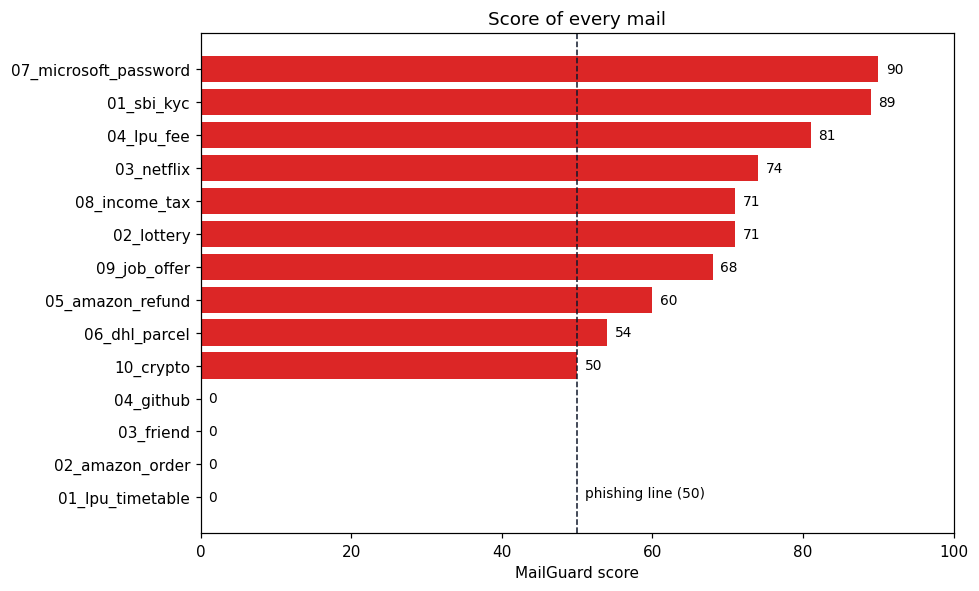

In [5]:
import matplotlib.pyplot as plt

plot = df.sort_values("score")
colors = ["#dc2626" if v == "phishing" else "#d97706" if v == "suspicious" else "#16a34a" for v in plot.verdict]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(plot.mail.str.replace(".txt", ""), plot.score, color=colors)
for y, s in enumerate(plot.score):
    ax.text(s + 1, y, str(s), va="center", fontsize=9)
ax.axvline(50, color="#0f172a", linestyle="--", linewidth=1)
ax.text(51, 0, "phishing line (50)", fontsize=9)
ax.set_xlabel("MailGuard score")
ax.set_title("Score of every mail")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

## 3. Which rules did the work?

Each rule is a subclass of `Rule` that overrides `check(mail)`. Counting the points each rule gave shows which signs of phishing are the strongest in this sample.

                               findings  points
sender does not match                14     174
asks for private details              8     170
suspicious link                      12     130
urgent / threatening language        16     128
too good to be true                   9      74
risky attachment                      2      32


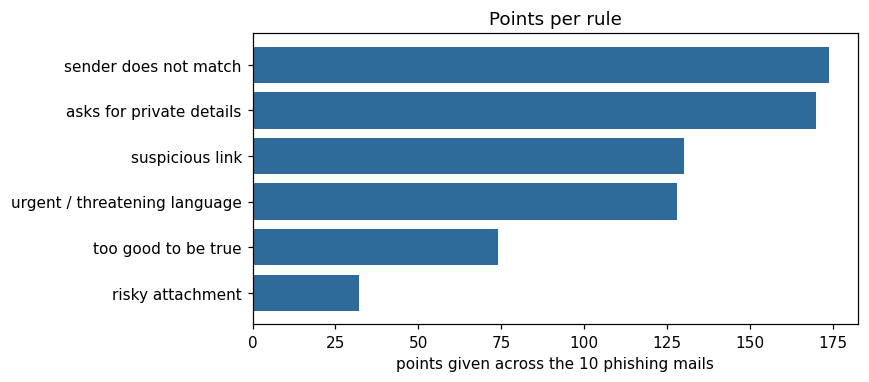

In [6]:
from collections import defaultdict

points = defaultdict(int)
hits = defaultdict(int)
for mail in load_mails(f"{DATA}/phishing"):
    for f in guard.analyse(mail).findings:
        points[f.rule] += f.points
        hits[f.rule] += 1

rules = pd.DataFrame({"findings": hits, "points": points}).sort_values("points")
print(rules.sort_values("points", ascending=False))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(rules.index, rules.points, color="#2f6b9a")
ax.set_xlabel("points given across the 10 phishing mails")
ax.set_title("Points per rule")
plt.tight_layout()
plt.show()

## 4. Practical 14: most common words

Words from the subject and body, lower-cased, stop words removed, counted with `collections.Counter`.

    word  in phishing  in normal
  refund            9          0
   hours            7          0
 details            6          0
 account            5          2
  within            5          0
     pay            5          0
     sbi            4          0
   today            4          0
customer            4          0
  update            4          0
    card            4          1
   login            4          0


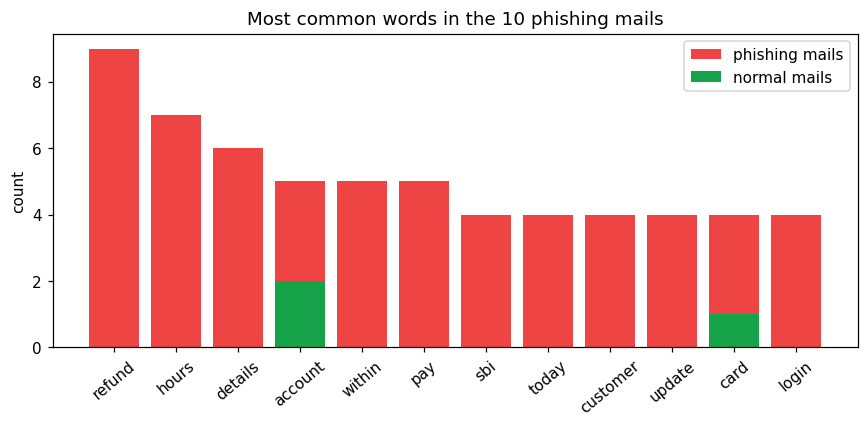

In [7]:
top = MailGuard.common_words(load_mails(f"{DATA}/phishing"), 12)
normal_words = dict(MailGuard.common_words(load_mails(f"{DATA}/safe"), 200))
words = pd.DataFrame(top, columns=["word", "in phishing"])
words["in normal"] = [normal_words.get(w, 0) for w in words.word]
print(words.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(words.word, words["in phishing"], color="#ef4444", label="phishing mails")
ax.bar(words.word, words["in normal"], color="#16a34a", label="normal mails")
ax.set_ylabel("count")
ax.set_title("Most common words in the 10 phishing mails")
ax.legend()
plt.xticks(rotation=40)
plt.tight_layout()
plt.show()

## 5. Links pulled out with regular expressions

The sender domains and link hosts are where most phishing mails give themselves away: look-alike spellings (`micros0ft`, `netf1ix`), bare IP addresses, shortened links and an `@` hidden inside the URL.

In [8]:
import re

links = []
for mail in load_mails(f"{DATA}/phishing"):
    for url in mail.urls:
        host = re.sub(r"^https?://", "", url).split("/")[0]
        links.append({"mail": mail.name.replace(".txt", ""), "sender domain": mail.sender_domain, "link host": host,
                      "https": url.startswith("https"), "ip": bool(re.search(r"\d+\.\d+\.\d+\.\d+", host))})
pd.DataFrame(links)

,mail,sender domain,link host,https,ip
0,01_sbi_kyc,sbi-kyc-update.in,sbi-kyc-update.in,False,False
1,03_netflix,netf1ix-support.com,bit.ly,True,False
2,04_lpu_fee,gmail.com,103.21.58.144,False,True
3,05_amazon_refund,amazon-secure-refund.co,amazon-secure-refund.co,True,False
4,06_dhl_parcel,dhl-parcel-track.info,dhl-parcel-track.info,False,False
5,07_microsoft_password,micros0ft-account.com,login-microsoftonline.account-verify.com@45.77...,True,True
6,08_income_tax,incometax-refund-gov.in,incometax-refund-gov.in,False,False
7,10_crypto,bitc0in-double.net,tinyurl.com,True,False


## 6. Add your own rule

Because every rule is just a subclass, adding one doesn't touch the rest of the code (polymorphism: `MailGuard.analyse` calls `check()` on whatever rules it was given).

In [9]:
class ShoutingRule(Rule):
    name = "subject in capitals"
    weight = 12

    def check(self, mail):
        letters = [c for c in mail.subject if c.isalpha()]
        upper = sum(c.isupper() for c in letters)
        return [self.hit(f"{upper} of {len(letters)} letters are capitals")] if letters and upper / len(letters) > 0.6 else []

test = Mail("From: Prize Desk <win@prize-desk.top>\nSubject: YOU WON A FREE IPHONE\n\nClaim your prize now, act now before it expires.")
print(MailGuard().analyse(test), "with the six default rules")

from pybench.mailguard import UrgencyRule, CredentialRule, LinkRule, SenderRule, MoneyRule, AttachmentRule
bigger = MailGuard([UrgencyRule(), CredentialRule(), LinkRule(), SenderRule(), MoneyRule(), AttachmentRule(), ShoutingRule()])
r = bigger.analyse(test)
print(r, "with ShoutingRule added")
for f in r.findings:
    print(" ", f)

mail: 26 (suspicious) with the six default rules
mail: 38 (suspicious) with ShoutingRule added
  +8 urgent / threatening language: 'act now'
  +8 urgent / threatening language: 'expires'
  +10 too good to be true: bait words: claim, prize, won
  +12 subject in capitals: 17 of 17 letters are capitals


## 7. Save the reports with pickle

In [10]:
reports, _ = guard.analyse_folder(f"{DATA}/phishing")
MailGuard.save(reports, "mailguard_reports.pkl")
loaded = MailGuard.load("mailguard_reports.pkl")
print(len(loaded), "reports saved and read back")
print(loaded[0])
print(MailGuard.load("no_such_file.pkl"), "<- a missing file gives an empty list instead of a crash")

10 reports saved and read back
('07_microsoft_password.txt', 90, 'phishing', ["+8 urgent / threatening language: 'expires'", "+8 urgent / threatening language: 'suspended'", '+20 asks for private details: mentions credentials, password', "+18 suspicious link: '@' inside a URL, the part before it is ignored by the browser", '+10 suspicious link: domain made to look official (login-microsoftonline.account-verify.com@45.77.12.9)', '+14 sender does not match: claims to be MICROSOFT but sent from micros0ft-account.com', '+12 sender does not match: look-alike characters in micros0ft-account.com (0 for o, 1 for l)'])
[] <- a missing file gives an empty list instead of a crash


## What I found

- All 10 phishing mails score 50 or more and none of the 4 normal mails gets a single point, but this is a small hand-made sample, so the real test would be a bigger public dataset.
- Asking for private details (OTP, CVV, Aadhaar, passwords) and a sender that doesn't match the brand it claims gave the most points.
- Word counts alone (practical 14) already separate the sets: *refund, hours, details, pay* never appear in the normal mails (*account* does, twice).
- Rules are easy to explain (every point has a reason), which a black-box classifier wouldn't give. A next step would be to learn the weights from labelled data instead of choosing them by hand.